In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
users = pd.read_csv("../data/ab_test_users_groups.csv")
users

,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9
3,U300003,A,2025-06-07,5
4,U300004,B,2025-12-25,11
...,...,...,...,...
6003,U301014,B,2026-03-28,10
6004,U301087,A,2025-06-27,10
6005,U301367,A,2025-09-03,8
6006,U301554,B,2025-09-25,9


In [3]:
events = pd.read_csv("../data/ab_test_events.csv")
events

,user_id,timestamp,event_type
0,U300281,2026-05-04 00:06:44,homework_completed
1,U300733,2026-05-04 00:19:56,homework_completed
2,U304499,2026-05-04 00:22:07,login
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started
...,...,...,...
179325,U300573,2026-05-24 23:44:15,homework_started
179326,U304499,2026-05-24 23:46:04,homework_completed
179327,U303438,2026-05-24 23:54:44,homework_completed
179328,U300573,2026-05-24 23:55:18,homework_started


In [4]:
users.info()
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      6008 non-null   object
 1   group        6008 non-null   object
 2   signup_date  6008 non-null   object
 3   grade        6008 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 187.9+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179330 entries, 0 to 179329
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   user_id     179330 non-null  object
 1   timestamp   179330 non-null  object
 2   event_type  179330 non-null  object
dtypes: object(3)
memory usage: 4.1+ MB


In [5]:
users.shape
events.shape

(179330, 3)

In [6]:
users.describe(include="all")

,user_id,group,signup_date,grade
count,6008,6008,6008,6008.000000
unique,6000,2,370,NaN
top,U301554,A,2025-04-04,NaN
freq,2,3005,31,NaN
mean,NaN,NaN,NaN,7.962051
std,NaN,NaN,NaN,1.998141
min,NaN,NaN,NaN,5.000000
25%,NaN,NaN,NaN,6.000000
50%,NaN,NaN,NaN,8.000000
75%,NaN,NaN,NaN,10.000000


In [7]:
events.describe(include='all')

,user_id,timestamp,event_type
count,179330,179330,179330
unique,6000,17284,5
top,U303729,2026-05-11 18:00:00,login
freq,842,4549,75552


In [8]:
users.isna().sum()

user_id        0
group          0
signup_date    0
grade          0
dtype: int64

In [9]:
events.isna().sum()

user_id       0
timestamp     0
event_type    0
dtype: int64

In [10]:
users.duplicated().sum()

np.int64(0)

In [11]:
events.duplicated().sum()

np.int64(2)

In [12]:
users["user_id"].duplicated().sum()

np.int64(8)

In [13]:
users["group"].value_counts()

group
A    3005
B    3003
Name: count, dtype: int64

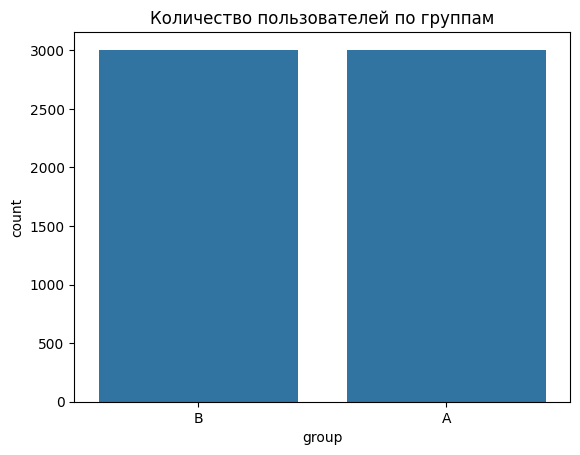

In [14]:
sns.countplot(data=users, x="group")
plt.title("Количество пользователей по группам")
plt.show()

Сколько пользователей одновременно находятся в A и B?

In [15]:
users[users['user_id'].duplicated(keep=False)].groupby('user_id')['group'].nunique()

user_id
U300357    2
U300460    2
U300920    2
U301014    2
U301087    2
U301367    2
U301554    2
U305216    2
Name: group, dtype: int64

In [16]:
users_in_a_and_b = users[users['user_id'].duplicated(keep=False)].groupby('user_id')['group'].nunique()
len(users_in_a_and_b[users_in_a_and_b==2])


8

При проверке корректности распределения пользователей обнаружено 8 уникальных user_id, одновременно присутствующих в группах A и B. Для предотвращения загрязнения экспериментальных групп эти пользователи будут исключены из дальнейшего анализа.

очистка конфликтующих пользователей и SRM-тест

In [17]:
users_in_a_and_b

user_id
U300357    2
U300460    2
U300920    2
U301014    2
U301087    2
U301367    2
U301554    2
U305216    2
Name: group, dtype: int64

In [18]:
users_clean = users[~users["user_id"].isin(users_in_a_and_b.index)]

users_clean

,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9
3,U300003,A,2025-06-07,5
4,U300004,B,2025-12-25,11
...,...,...,...,...
5995,U305995,A,2025-09-03,8
5996,U305996,B,2025-07-22,6
5997,U305997,A,2025-08-08,5
5998,U305998,A,2026-03-21,6


In [19]:
users_clean["user_id"].nunique()

5992

In [20]:
users_clean['group'].value_counts()

group
A    2997
B    2995
Name: count, dtype: int64

In [21]:
from scipy.stats import chisquare

observed = [2997, 2995] #фактически
expected = [2996, 2996] #ожидалось

result_SRM = chisquare(f_obs=observed, f_exp=expected)

print(result_SRM)

Power_divergenceResult(statistic=np.float64(0.0006675567423230974), pvalue=np.float64(0.9793872546704734))


p-value = 0,9794 > α = 0,001

Статистически значимый SRM не обнаружен

### Проверка качества событий

В таблице events обнаружено **179 330 записей**, относящихся к **6 000 уникальным пользователям**.

Распределение событий по типам:
- `login` — 75 552;
- `homework_started` — 68 317;
- `homework_completed` — 28 995;
- `return_visit_d7` — 4 519;
- `return_visit_d14` — 1 947.

Наибольшее количество записей приходится на входы в систему и начало выполнения домашних заданий.

Количество уникальных пользователей в логах совпадает с количеством уникальных пользователей в исходной таблице распределения. Однако это ещё не подтверждает полного совпадения идентификаторов.

Для дальнейшего анализа необходимо проверить наличие неизвестных пользователей, удалить технические дубликаты и исследовать аномальную активность.

In [22]:
events['event_type'].value_counts()

event_type
login                 75552
homework_started      68317
homework_completed    28995
return_visit_d7        4519
return_visit_d14       1947
Name: count, dtype: int64

In [23]:
events['user_id'].nunique()

6000

In [24]:
events[~events['user_id'].isin(users['user_id'])]


,user_id,timestamp,event_type


**Проверка соответствия идентификаторов пользователей**

Проверка показала, что все `user_id` из таблицы событий `events` присутствуют в исходной таблице распределения пользователей `users`. Неизвестных идентификаторов не обнаружено.

При этом 8 пользователей с конфликтующим назначением в группы A и B необходимо исключить из событий перед расчётом продуктовых метрик.

In [25]:
events_per_user = events.groupby('user_id')['event_type'].size()

events_per_user.describe()

count    6000.000000
mean       29.888333
std        34.001998
min         6.000000
25%        24.000000
50%        28.000000
75%        33.000000
max       842.000000
Name: event_type, dtype: float64

**Поиск выбросов**

IQR = 33 - 24 = 9

Верхняя граница по правилу 1.5 * IQR:

Q3 + 1.5 * IQR = 33 + 13.5 = 46.5

То есть пользователи с количеством событий от 47 будут считаться потенциальными выбросами.

In [26]:
events_per_user

user_id
U300000    33
U300001    30
U300002    29
U300003    25
U300004    29
           ..
U305995    34
U305996    28
U305997    30
U305998    21
U305999    29
Name: event_type, Length: 6000, dtype: int64

In [27]:
events_per_user[events_per_user > 46].count()

np.int64(42)

In [28]:
events_per_user.sort_values(ascending=False).head()

user_id
U303729    842
U304167    829
U305378    793
U302840    790
U304266    781
Name: event_type, dtype: int64

In [29]:
events[events['user_id']=='U303729']

,user_id,timestamp,event_type
8,U303729,2026-05-04 00:28:33,homework_started
36,U303729,2026-05-04 02:27:01,homework_completed
42,U303729,2026-05-04 03:06:31,homework_completed
45,U303729,2026-05-04 03:22:50,login
51,U303729,2026-05-04 03:29:17,homework_started
...,...,...,...
177018,U303729,2026-05-24 19:26:16,login
177380,U303729,2026-05-24 19:42:00,homework_completed
178496,U303729,2026-05-24 20:31:55,login
179274,U303729,2026-05-24 21:29:07,login


In [30]:
events[events['user_id']=='U303729']['event_type'].value_counts()

event_type
homework_started      308
homework_completed    285
login                 248
return_visit_d14        1
Name: count, dtype: int64

In [31]:
events_per_user[events_per_user > 100].count()

np.int64(12)

In [32]:
events_per_user[events_per_user > 500].count()

np.int64(12)

In [33]:
suspicious_users = events_per_user[events_per_user > 500].index

suspicious_users

Index(['U300158', 'U300281', 'U300573', 'U300733', 'U302379', 'U302840',
       'U303438', 'U303729', 'U304167', 'U304266', 'U304499', 'U305378'],
      dtype='object', name='user_id')

In [34]:
users_clean[users_clean["user_id"].isin(suspicious_users)]["group"].value_counts()

group
B    7
A    5
Name: count, dtype: int64

У нас есть 12 пользователей с экстремально высокой активностью (более 500 событий). Они составляют 0,2% выборки и присутствуют в обеих группах: 5 в A и 7 в B.

Пока мы можем назвать их потенциальными аномалиями, но не доказанными ботами.

In [35]:
events.duplicated().sum()

np.int64(2)

In [36]:
events_clean = events.drop_duplicates().copy()

suspicious_events = (
    events[events["user_id"].isin(suspicious_users)]
    .groupby(["user_id", "event_type"])
    .size()
    .unstack(fill_value=0)
)

suspicious_events

event_type,homework_completed,homework_started,login,return_visit_d14,return_visit_d7
user_id,,,,,
U300158,255,234,248,0,1
U300281,233,258,268,0,1
U300573,255,269,246,0,1
U300733,246,259,264,0,1
U302379,254,257,253,0,1
U302840,256,243,291,0,0
U303438,223,230,258,0,0
U303729,285,308,248,1,0
U304167,290,258,280,0,1


### Проверка дубликатов и аномальной активности

В таблице событий обнаружены 2 полных дубликата, которые исключаются из дальнейших расчётов.

Анализ активности выявил 12 пользователей (0,2% выборки), совершивших более 500 событий каждый. У этих пользователей наблюдаются сотни входов в систему, запусков и завершений домашних заданий.

Подобная активность существенно отличается от поведения большинства пользователей: медианное количество событий составляет 28.

При этом высокая активность сама по себе не доказывает автоматизацию. Выявленные пользователи рассматриваются как потенциальные аномалии. Для оценки устойчивости результатов A/B-теста рекомендуется дополнительно сравнить ключевые метрики с их включением и исключением.

In [37]:
events_clean = events_clean[~events_clean["user_id"].isin(users_in_a_and_b[users_in_a_and_b==2].index)]
events_clean["user_id"].isin(users_in_a_and_b.index).sum()

np.int64(0)

In [38]:
ab_events = pd.merge(users_clean, events_clean, how='left', on='user_id')

ab_events

,user_id,group,signup_date,grade,timestamp,event_type
0,U300000,B,2026-03-09,5,2026-05-04 19:36:00,login
1,U300000,B,2026-03-09,5,2026-05-07 19:35:00,login
2,U300000,B,2026-03-09,5,2026-05-07 19:42:00,homework_started
3,U300000,B,2026-03-09,5,2026-05-08 17:05:00,login
4,U300000,B,2026-03-09,5,2026-05-08 17:11:00,homework_started
...,...,...,...,...,...,...
179106,U305999,A,2025-06-19,11,2026-05-20 19:56:00,homework_started
179107,U305999,A,2025-06-19,11,2026-05-20 20:16:00,homework_completed
179108,U305999,A,2025-06-19,11,2026-05-21 20:47:00,login
179109,U305999,A,2025-06-19,11,2026-05-21 20:53:00,homework_started


In [39]:
ab_events["user_id"].nunique()

5992

In [40]:
ab_events.to_csv("../data/ab_events_clean.csv", index=False)